# Lab 1.14 · Image generation inference bottlenecks

**15–20 minutes · CPU**

Read the [lab guide](README.md), then run the setup. Replace each `return None` with your implementation and rerun its check.

## Concepts and worked example

Why can image generation spend so much time in attention even with a smaller model?

Kiely contrasts repeated denoising over a whole latent grid with single-token LLM decode. In a diffusion transformer, global self-attention can compare every spatial patch token with every other patch token during each denoiser evaluation. At a fixed patch size, doubling both latent axes quadruples token count. Full attention then has sixteen times as many query-key pairs.

For a 16 × 16 latent with 2 × 2 patches, there are 64 tokens and 4,096 pairs per head. With head width d, the score product and weighted value product each cost about `2 × tokens² × d` FLOP per head. This exercise estimates those products alone. Softmax, projections, other layers, and memory traffic need separate accounting. The estimate explains why compute can dominate. Materializing large score matrices or changing the attention implementation can shift the actual bottleneck.

The latency column is a compute floor for the two attention matrix products only. The estimate holds the head layout and number of attention blocks fixed. The 16× result refers to their FLOP count. It does not predict a 16× increase in end-to-end latency.

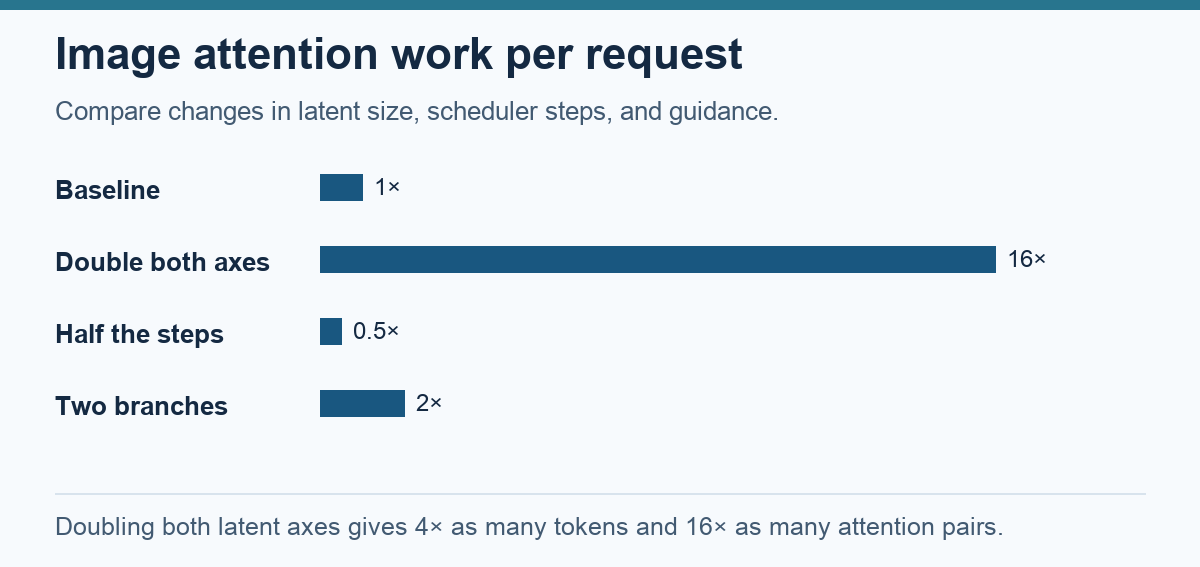

## Exercise map

| Exercise | What you will do | What to inspect |
| --- | --- | --- |
| 1. Count spatial attention work | Convert a latent grid into patch tokens and FLOP per block. | Compare doubling one axis with doubling both. |
| 2. Scale to a denoising budget | Multiply by model evaluations and attention blocks. | Compare changing resolution with changing steps or guidance. |

Reading companion for Section 2.4.3, p. 67 of *Inference Engineering* by Philip Kiely (Baseten Books).

In [ ]:
peak = 60e12  # FLOP/s, used only to estimate an optimistic compute floor

## Exercise 1. Count patch tokens and work

Return (tokens, FLOP) for global attention in one block. Use non-overlapping square patches and assume both grid dimensions divide exactly by the patch size. Count two matrix products for each head.

**Implementation hint** · Find the patch count along each axis, multiply to get tokens, then square the token count to get pairs per head.

**Interpret the result** · Doubling one axis doubles the token count and quadruples the pair count.

In [ ]:
def attention_cost(height, width, patch, heads, head_width):
    return None

In [ ]:
base = attention_cost(16, 16, 2, 4, 32)
if base is not None:
    assert base == (64, 2_097_152)
    assert attention_cost(16, 32, 2, 4, 32)[1] == 4 * base[1]
    assert attention_cost(32, 32, 2, 4, 32)[1] == 16 * base[1]
    print("PASS — baseline tokens and FLOP:", base)
else:
    print("Complete the implementation and any earlier exercises, then rerun this check.")

## Exercise 2. Estimate work across the request

Multiply attention FLOP per block by blocks, scheduler steps, and prediction branches per step. A conditional and an unconditional branch can be batched in a single Python call but still contribute work. Return total FLOP and an optimistic compute time floor in milliseconds.

**Implementation hint** · Calculate how many times the attention block runs across the request, multiply by its FLOP count, then divide by peak FLOP/s.

**Interpret the result** · Half as many steps with two branches per step gives the same modeled work as the single-branch baseline.

In [ ]:
def request_cost(block_flop, blocks, steps, branches):
    return None

In [ ]:
if base is not None and request_cost(base[1], 12, 20, 1) is not None:
    bigger = attention_cost(32, 32, 2, 4, 32)[1]
    baseline = request_cost(base[1], 12, 20, 1)[0]
    for label, cost, steps, branches in [
        ("baseline", base[1], 20, 1), ("double both axes", bigger, 20, 1),
        ("half the steps", base[1], 10, 1), ("two branches", base[1], 20, 2),
    ]:
        operations, time_ms = request_cost(cost, 12, steps, branches)
        print(f"{label:17s} {operations / baseline:4.1f}× work, {time_ms:.4f} ms compute floor")
    assert baseline == 503_316_480
    assert abs(request_cost(base[1], 12, 20, 1)[1] - 0.008388608) < 1e-12
    assert request_cost(bigger, 12, 20, 1)[0] == 16 * baseline
    assert request_cost(base[1], 12, 10, 2)[0] == baseline
    print("PASS — compared resolution, steps, and guidance at fixed architecture")
else:
    print("Complete the implementation and any earlier exercises, then rerun this check.")

## Wrap-up

How would windowed attention change the pair count? Which quality settings would you hold fixed when measuring the real effect of reducing steps or resolution?